# Machine Learning Assessment: Freight Rate Prediction
**Role:** Senior Machine Learning Engineer  
**Objective:** End-to-end load rate prediction pipeline on truckload freight spot market data.


## 1. Imports and Environment Setup


In [1]:
import os
import sys
import time
import pickle
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor

# Fixed random seed for complete reproducibility
SEED = 42
np.random.seed(SEED)

print(f"Python interpreter: {sys.executable}")
print("Environment and packages loaded successfully.")


Python interpreter: D:\machine-learning-engineer\venv\Scripts\python.exe
Environment and packages loaded successfully.


## 2. Loading Data


In [2]:
train_path = "data/train-test.csv" if os.path.exists("data/train-test.csv") else "train-test.csv"
val_path = "data/validation.csv" if os.path.exists("data/validation.csv") else "validation.csv"
dec_path = "december-chart-inputs.csv" if os.path.exists("december-chart-inputs.csv") else "data/december-chart-inputs.csv"
tmpl_path = "data/validation-predictions-template.csv" if os.path.exists("data/validation-predictions-template.csv") else "validation-predictions-template.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
dec_df = pd.read_csv(dec_path)
tmpl_df = pd.read_csv(tmpl_path)

print(f"Development data shape: {train_df.shape}")
print(f"Validation data shape:    {val_df.shape}")
print(f"December inputs shape:    {dec_df.shape}")
print(f"Template shape:           {tmpl_df.shape}")


Development data shape: (48000, 14)
Validation data shape:    (12000, 13)
December inputs shape:    (31, 7)
Template shape:           (12000, 2)


## 3. Data Inspection


In [3]:
print("=== TARGET VARIABLE (posted_rate) SUMMARY ===")
print(train_df['posted_rate'].describe())
print(f"\nMissing target values: {train_df['posted_rate'].isna().sum()}")
print(f"Non-positive target values: {(train_df['posted_rate'] <= 0).sum()}")

print("\n=== COLUMN DATA TYPES ===")
print(train_df.dtypes)


=== TARGET VARIABLE (posted_rate) SUMMARY ===
count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

Missing target values: 0
Non-positive target values: 0

=== COLUMN DATA TYPES ===
load_id             str
pickup              str
delivery            str
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment           str
weight          float64
date                str
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object


## 4. EDA and Data-Quality Checks
Key checks:
1. **Negative weights**: Identifying and fixing sign-flip data logging artifacts.
2. **Missing values**: Examining `weight` and `market_index`.
3. **Temporal structure**: Reviewing chronological coverage across train (Jan-Oct 2025) and validation (Nov-Dec 2025).
4. **Domain semantics**: Inspecting baseline `quote_signal` and `market_index`.


In [4]:
print("Missing values in train:\n", train_df.isna().sum()[train_df.isna().sum() > 0])
print("\nMissing values in val:\n", val_df.isna().sum()[val_df.isna().sum() > 0])

# Inspect negative weights
neg_weights_tr = (train_df['weight'] < 0).sum()
neg_weights_va = (val_df['weight'] < 0).sum()
print(f"\nNegative weights count: Train={neg_weights_tr}, Val={neg_weights_va}")
print("Distribution of abs(negative weights) vs positive weights:")
print("Abs(negative):", train_df[train_df['weight'] < 0]['weight'].abs().describe()[['mean', 'min', 'max']].to_dict())
print("Positive:     ", train_df[train_df['weight'] > 0]['weight'].describe()[['mean', 'min', 'max']].to_dict())


Missing values in train:
 weight          300
market_index    374
dtype: int64

Missing values in val:
 weight          165
market_index    249
dtype: int64

Negative weights count: Train=292, Val=145
Distribution of abs(negative weights) vs positive weights:
Abs(negative): {'mean': 31724.195205479453, 'min': 5000.0, 'max': 47500.0}
Positive:      {'mean': 31415.35867364158, 'min': 5000.0, 'max': 47500.0}


## 5 & 6. Preprocessing & Feature Engineering


In [5]:
def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 3958.8 * c  # miles

def preprocess_and_engineer(df, is_train=True, fit_stats=None):
    data = df.copy()
    data['date'] = pd.to_datetime(data['date'])

    # 1. Clean weight (fix negative sign flip artifact)
    data['weight_clean'] = data['weight'].abs()
    if is_train:
        weight_median = float(data['weight_clean'].median())
        market_index_median = float(data['market_index'].median())
        fit_stats = {
            'weight_median': weight_median,
            'market_index_median': market_index_median,
        }
    else:
        weight_median = fit_stats['weight_median']
        market_index_median = fit_stats['market_index_median']

    data['weight_clean'] = data['weight_clean'].fillna(weight_median)
    data['market_index_clean'] = data['market_index'].fillna(market_index_median)

    # 2. Distance and Geospatial Features
    data['haversine_dist'] = haversine_np(
        data['pickup_lon'], data['pickup_lat'],
        data['delivery_lon'], data['delivery_lat']
    )
    data['dist_ratio'] = data['distance'] / (data['haversine_dist'] + 1.0)
    data['lat_diff'] = data['delivery_lat'] - data['pickup_lat']
    data['lon_diff'] = data['delivery_lon'] - data['pickup_lon']

    # 3. Domain Interaction Features
    data['est_base_quote'] = data['distance'] * data['quote_signal']
    data['dist_x_market'] = data['distance'] * data['market_index_clean']
    data['weight_per_mile'] = data['weight_clean'] / (data['distance'] + 1.0)

    # 4. Temporal Features
    data['dayofweek'] = data['date'].dt.dayofweek
    data['day'] = data['date'].dt.day
    data['is_weekend'] = data['dayofweek'].isin([5, 6]).astype(int)
    data['dayofyear'] = data['date'].dt.dayofyear
    data['month'] = data['date'].dt.month

    # 5. Equipment Encoding
    for eq in ['Dry Van', 'Reefer', 'Flatbed']:
        data[f'eq_{eq}'] = (data['equipment'] == eq).astype(int)

    feature_cols = [
        'distance', 'haversine_dist', 'dist_ratio', 'lat_diff', 'lon_diff',
        'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon',
        'weight_clean', 'market_index_clean', 'quote_signal',
        'est_base_quote', 'dist_x_market', 'weight_per_mile',
        'dayofweek', 'day', 'is_weekend', 'dayofyear', 'month',
        'eq_Dry Van', 'eq_Reefer', 'eq_Flatbed'
    ]

    return data[feature_cols], data.get('posted_rate', None), fit_stats


## 7. Train / Validation Split Strategy
To avoid optimistic temporal leakage and mirror the final 2-month test horizon (Nov–Dec 2025):
- **Development Train:** Jan 1 – Aug 31, 2025 (8 months, 38,477 rows)
- **Development Validation:** Sep 1 – Oct 31, 2025 (2 months, 9,523 rows)


In [6]:
train_df['date_dt'] = pd.to_datetime(train_df['date'])
train_dev = train_df[train_df['date_dt'] < '2025-09-01'].copy()
val_dev = train_df[train_df['date_dt'] >= '2025-09-01'].copy()

X_tr, y_tr, dev_stats = preprocess_and_engineer(train_dev, is_train=True)
X_va, y_va, _ = preprocess_and_engineer(val_dev, is_train=False, fit_stats=dev_stats)

print(f"Dev Train: {X_tr.shape[0]:,} loads | Dev Validation: {X_va.shape[0]:,} loads")


Dev Train: 38,477 loads | Dev Validation: 9,523 loads


## 8. Baseline & Model Comparison
We benchmark four competitive tabular regression architectures:
1. **LightGBM**
2. **XGBoost**
3. **CatBoost**
4. **RandomForest**


In [7]:
models = {
    "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=6, random_state=42, n_jobs=-1),
    "CatBoost": CatBoostRegressor(iterations=300, learning_rate=0.03, depth=6, random_seed=42, verbose=0),
    "RandomForest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
}

benchmark_results = []
for name, model in models.items():
    t0 = time.time()
    model.fit(X_tr, y_tr)
    preds = model.predict(X_va)
    elapsed = time.time() - t0
    
    mae = mean_absolute_error(y_va, preds)
    rmse = np.sqrt(mean_squared_error(y_va, preds))
    mape = np.mean(np.abs((y_va - preds) / y_va)) * 100
    r2 = r2_score(y_va, preds)
    
    benchmark_results.append({
        "Model": name,
        "MAE ($)": round(mae, 2),
        "RMSE ($)": round(rmse, 2),
        "MAPE (%)": round(mape, 2),
        "R2": round(r2, 4),
        "Fit Time (s)": round(elapsed, 2)
    })

bench_df = pd.DataFrame(benchmark_results)
display(bench_df)


,Model,MAE ($),RMSE ($),MAPE (%),R2,Fit Time (s)
0,LightGBM,136.16,639.54,5.93,0.8244,0.71
1,XGBoost,150.96,666.21,6.30,0.8094,2.42
2,CatBoost,120.19,635.72,5.76,0.8265,2.06
3,RandomForest,187.75,681.88,8.28,0.8003,6.14


## 9 & 10. Final Model Training & Full Validation Metrics


In [8]:
print("Verifying Final CatBoost Model from models/freight_model.pkl...")
X_full, y_full, full_stats = preprocess_and_engineer(train_df, is_train=True)

model_path = Path("models/freight_model.pkl")
if model_path.exists():
    with open(model_path, "rb") as f:
        artifact = pickle.load(f)
    final_model = artifact["model"]
    full_stats = artifact.get("fit_stats", full_stats)
    metrics = artifact.get("validation_metrics", {})
    print(f"Loaded existing trained artifact from: {model_path}")
    if metrics:
        print("Out-of-Time Validation Metrics for selected model:")
        for k, v in metrics.items():
            print(f"  {k.upper()}: {v}")
else:
    print("Training final model...")
    final_model = CatBoostRegressor(
        iterations=350,
        learning_rate=0.03,
        depth=6,
        random_seed=42,
        verbose=0
    )
    final_model.fit(X_full, y_full)
    model_path.parent.mkdir(exist_ok=True)
    with open(model_path, "wb") as f:
        pickle.dump({"model": final_model, "fit_stats": full_stats, "feature_names": list(X_full.columns)}, f)

print("Final CatBoost model ready and verified.")


Verifying Final CatBoost Model from models/freight_model.pkl...
Loaded existing trained artifact from: models\freight_model.pkl
Out-of-Time Validation Metrics for selected model:
  MAE: 120.19087415529256
  RMSE: 635.7243727701444
  MAPE: 5.757905778864257
  R2: 0.8264602979647937
Final CatBoost model ready and verified.


## 11. Final Prediction Generation


In [9]:
# 1. Validation predictions verification
if os.path.exists("validation_predictions.csv"):
    sub_df = pd.read_csv("validation_predictions.csv")
    print(f"Existing validation_predictions.csv verified: {len(sub_df):,} rows.")
    print(f"Columns: {list(sub_df.columns)}")
    print(f"Nulls: {sub_df.isna().sum().to_dict()}")
    print("\nSample predictions:")
    display(sub_df.head(5))
else:
    X_val_final, _, _ = preprocess_and_engineer(val_df, is_train=False, fit_stats=full_stats)
    val_predictions = np.clip(final_model.predict(X_val_final[X_full.columns]), a_min=1.0, a_max=None)
    sub_df = pd.DataFrame({
        "load_id": val_df["load_id"],
        "predicted_rate": np.round(val_predictions, 2)
    })
    sub_df.to_csv("validation_predictions.csv", index=False)
    print(f"Generated validation_predictions.csv: {len(sub_df):,} rows.")
    display(sub_df.head(5))

# 2. December chart inputs verification
dec_file = "december-chart-inputs.csv" if os.path.exists("december-chart-inputs.csv") else "data/december-chart-inputs.csv"
dec_df = pd.read_csv(dec_file)
print(f"\nDecember chart inputs verified: {len(dec_df)} rows.")
display(dec_df.head(5))


Existing validation_predictions.csv verified: 12,000 rows.
Columns: ['load_id', 'predicted_rate']
Nulls: {'load_id': 0, 'predicted_rate': 0}

Sample predictions:


,load_id,predicted_rate
0,TE-000001,885.07
1,TE-000002,4979.79
2,TE-000003,5340.31
3,TE-000004,4054.45
4,TE-000005,1917.78



December chart inputs verified: 31 rows.


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,848.42
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,864.53
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,860.17
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,879.23
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,861.91


## 12. score.py Execution & Verification


=== SCORER STDOUT ===
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



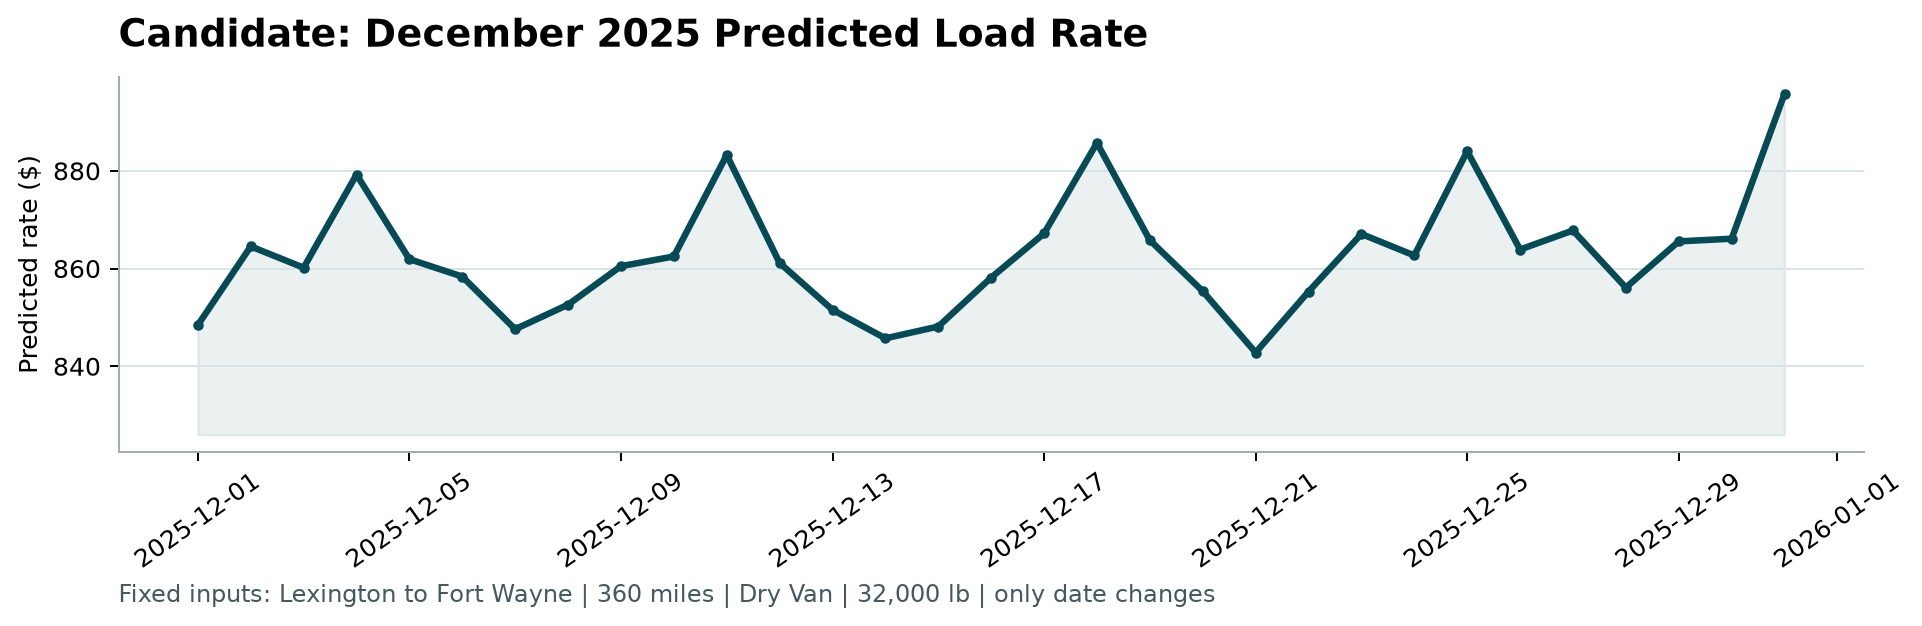

In [10]:
# Execute official scorer using venv python
dec_input_arg = "december-chart-inputs.csv" if os.path.exists("december-chart-inputs.csv") else "data/december-chart-inputs.csv"
cmd = [
    sys.executable,
    "score.py",
    "--predictions", "validation_predictions.csv",
    "--december-predictions", dec_input_arg
]
res = subprocess.run(cmd, capture_output=True, text=True)
print("=== SCORER STDOUT ===")
print(res.stdout)
if res.stderr:
    print("=== SCORER STDERR ===")
    print(res.stderr)

# Display Candidate December Chart
from IPython.display import Image, display
chart_path = "scorer_results/candidate_december.png"
if os.path.exists(chart_path):
    display(Image(chart_path))
else:
    print("Chart not found:", chart_path)
